# Mango Quality Prediction — Data → ML Pipeline (Stage 1–10)

**Đề tài:** Dự đoán sự suy giảm chất lượng và thời hạn sử dụng còn lại của xoài từ lịch sử phơi nhiễm trong chuỗi cung ứng lạnh.

Notebook này thực hiện kiểm kê dữ liệu, hiểu cấu trúc, làm sạch, tái tạo cold-chain trajectory, liên kết exposure với quality, xây dựng đặc trưng/nhãn, chống leakage, EDA và đóng băng dataset.

> **Cách chạy:** đặt dữ liệu đã giải nén vào `data/raw/` (bên trong có `0_README.txt`, `01_src_subset_dataset_T_H/`, `03_src_subset_dataset_W/`...). Hoặc chỉnh `DATA_RAW` ở Stage 0. Chạy lần lượt từ trên xuống dưới.

**Nguyên tắc:** dữ liệu gốc là nguồn sự thật; không tự suy diễn vị trí đo, timezone, ngưỡng sinh học hoặc quan hệ ID khi tài liệu không xác nhận. Các giả định được ghi trong `outputs/reports/assumptions_and_warnings.md`.

## STAGE 0 — Cấu hình và quy ước

- Chỉ dùng file sensor theo từng chặng để dựng trajectory; file `00_All_Recording...` là bản ghi toàn trình dùng đối chiếu, không cộng lẫn với các chặng để tránh đếm đôi.
- `T_mangoes` được giữ nguyên tên gốc và mô tả trung tính là *temperature channel associated with mango* cho tới khi vị trí lắp đặt được xác nhận bằng protocol/ảnh/tài liệu. Không gọi là nhiệt độ tâm quả.
- `Box_ID` lấy từ tọa độ cuối tên file sensor. Quality ID chỉ được parse khi định dạng cột cho phép.
- Timestamp trong dữ liệu ở dạng ngày/giờ không có timezone rõ ràng; giữ dạng naive local time, không tự gán UTC.
- Ngưỡng chilling injury / heat stress cần được nhóm xác nhận từ tài liệu sinh học trước khi bật feature degree-hours.

In [1]:
from pathlib import Path
import os, re, json, hashlib, warnings, zipfile
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 180)

PROJECT_ROOT = Path.cwd()
# Nếu notebook được mở từ thư mục notebooks/, lùi một cấp để tìm data/
if not (PROJECT_ROOT / 'data').exists() and (PROJECT_ROOT.parent / 'data').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_RAW = Path(os.environ.get('MANGO_DATA_RAW', PROJECT_ROOT / 'data' / 'raw')).expanduser()
OUTPUT = PROJECT_ROOT / 'outputs'
for folder in ['tables','figures','reports','processed']:
    (OUTPUT / folder).mkdir(parents=True, exist_ok=True)
( PROJECT_ROOT / 'configs').mkdir(exist_ok=True)

# Các ngưỡng để None mặc định vì cần xác nhận tài liệu chuyên ngành trước khi tính.
CONFIG = {
    'expected_sampling_minutes': 5,
    'group_k_folds': 5,
    'cold_injury_threshold_c': None,
    'heat_stress_threshold_c': None,
    'storage_day_labels': [0,3,6,9,12,15],
    'date_format': '%d/%m/%Y %H:%M',
    'random_state': 42,
}
with open(PROJECT_ROOT / 'configs' / 'config.json','w',encoding='utf-8') as f:
    json.dump(CONFIG,f,ensure_ascii=False,indent=2)

print('PROJECT_ROOT:', PROJECT_ROOT)
print('DATA_RAW:', DATA_RAW)
print('DATA_RAW exists:', DATA_RAW.exists())
if not DATA_RAW.exists():
    raise FileNotFoundError(f'Không tìm thấy dữ liệu tại {DATA_RAW}. Hãy giải nén dataset vào data/raw hoặc đặt biến môi trường MANGO_DATA_RAW.')

PROJECT_ROOT: /mnt/data/mango_quality_project
DATA_RAW: /mnt/data/testdata
DATA_RAW exists: True


## STAGE 1 — Data inventory

### 1.1 Liệt kê file và phân nhóm

Nhận diện sensor logs theo chặng/toàn trình, quality (Weight/Color/PH/TSS), metadata, ảnh, scripts và kết quả xử lý. Regex chỉ phân loại tên file; file không khớp được giữ lại trong báo cáo thay vì bỏ qua.

In [2]:
all_files = sorted(p for p in DATA_RAW.rglob('*') if p.is_file())

def classify_file(p: Path):
    n, parent = p.name, p.parent.name
    if n.lower() in {'0_readme.txt','manifest.txt'} or n.lower().startswith('read.me'):
        return 'documentation'
    if p.suffix.lower() == '.r': return 'scripts'
    if p.suffix.lower() in {'.jpg','.jpeg','.png','.tif','.tiff'}: return 'photos_or_figures'
    if p.suffix.lower() in {'.xlsx','.xls','.csv','.html','.tab'}: return 'metadata_or_processed'
    if re.search(r'_(Temp|Temp_Hum)\.txt$', n): return 'sensor_log'
    if re.match(r'^\d+_(Weight|Color|PH|TSS)_', n, re.I): return 'quality_measurement'
    if 'Storage_Room_Temp_Hum' in n: return 'storage_room_sensor'
    return 'unclassified'

inventory = pd.DataFrame([{
    'relative_path': str(p.relative_to(DATA_RAW)).replace('\\','/'),
    'folder': p.parent.name, 'filename': p.name,
    'extension': p.suffix.lower() or '(no extension)',
    'size_bytes': p.stat().st_size, 'category': classify_file(p)
} for p in all_files])
inventory.to_csv(OUTPUT/'tables'/'01_data_inventory.csv',index=False,encoding='utf-8-sig')
folder_inventory = (inventory.groupby(['folder','category','extension'],dropna=False)
                    .agg(file_count=('filename','size'), total_size_bytes=('size_bytes','sum'))
                    .reset_index().sort_values(['folder','category']))
folder_inventory.to_csv(OUTPUT/'tables'/'01b_folder_inventory.csv',index=False,encoding='utf-8-sig')
print('Total files:',len(inventory))
display(folder_inventory)
display(inventory.groupby('category').size().rename('file_count').to_frame())

Total files: 563


,folder,category,extension,file_count,total_size_bytes
0,00_script,scripts,.r,6,105301
1,01_src_subset_dataset_T_H,sensor_log,.txt,341,1226356
2,02_res_subset_dataset_T_H,metadata_or_processed,.csv,1,83077
3,02_res_subset_dataset_T_H,metadata_or_processed,.html,1,90462
4,02_res_subset_dataset_T_H,photos_or_figures,.png,62,1203207
5,02_res_subset_dataset_T_H,unclassified,.txt,1,79939
6,03_src_subset_dataset_W,documentation,.txt,1,106
7,03_src_subset_dataset_W,quality_measurement,.txt,5,2915
8,04_res_subset_dataset_W,photos_or_figures,.png,49,758870
9,04_res_subset_dataset_W,unclassified,.txt,1,1121


,file_count
category,
documentation,7
metadata_or_processed,5
photos_or_figures,180
quality_measurement,17
scripts,6
sensor_log,343
unclassified,5


### 1.1b Kiểm định quy tắc đặt tên bằng Regex

RegexOne: https://regexone.com/ — tham khảo character classes, repetition, anchors và capture groups. Các pattern dưới đây được thiết kế theo cấu trúc tên file thực tế trong README của dataset.

In [3]:
PATTERNS = {
 'sensor_step': re.compile(r'^(?P<step>\d+)_(?P<step_name>.+?)_(?P<x>\d+)_(?P<y>\d+)_(?P<z>\d+)_(?P<mode>Temp|Temp_Hum)\.txt$', re.I),
 'sensor_all': re.compile(r'^00_All_Recording_.+_(?P<x>\d+)_(?P<y>\d+)_(?P<z>\d+)_(?P<mode>Temp|Temp_Hum)\.txt$', re.I),
 'quality': re.compile(r'^(?P<configuration>\d+)_(?P<attribute>Weight|Color|PH|TSS)_(?P<temperature>\d+)C(?:_(?P<sample>.+))?\.txt$', re.I),
 'photo': re.compile(r'^(?P<x>\d+)_(?P<y>\d+)_(?P<z>\d+)_(?P<temperature>\d+)C_(?P<day>D\d+)\.(?:jpg|jpeg|png)$', re.I),
}

def match_pattern(name):
    for label, pattern in PATTERNS.items():
        m=pattern.match(name)
        if m: return label, m.groupdict()
    return None, {}

parsed=[]
for p in all_files:
    label, groups=match_pattern(p.name)
    parsed.append({'relative_path':str(p.relative_to(DATA_RAW)),'pattern':label or 'NO_MATCH',**groups})
regex_audit=pd.DataFrame(parsed)
regex_audit.to_csv(OUTPUT/'tables'/'01c_regex_audit.csv',index=False,encoding='utf-8-sig')
print('Regex matched:',(regex_audit.pattern!='NO_MATCH').sum(),'/',len(regex_audit))
display(regex_audit[regex_audit.pattern=='NO_MATCH'].head(30))

Regex matched: 367 / 563


,relative_path,pattern,step,step_name,x,y,z,mode,configuration,attribute,temperature,sample,day
0,00_script/01to02_script_temp_hum.R,NO_MATCH,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,00_script/03to04_script_weight.R,NO_MATCH,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,00_script/05to06_script_color.R,NO_MATCH,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,00_script/07to08_script_ph.R,NO_MATCH,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,00_script/09to10_script_tss.R,NO_MATCH,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,00_script/11to12_script_storage_temp.R,NO_MATCH,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
347,02_res_subset_dataset_T_H/Box_1_1_1.png,NO_MATCH,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
348,02_res_subset_dataset_T_H/Box_1_1_12.png,NO_MATCH,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
349,02_res_subset_dataset_T_H/Box_1_1_12_Step_Numb...,NO_MATCH,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
350,02_res_subset_dataset_T_H/Box_1_1_1_Step_Numbe...,NO_MATCH,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 1.2 Cấu trúc thư mục

Notebook không tạo symlink hoặc di chuyển file gốc. Thay vào đó, nó lập manifest đường dẫn tương đối để bảo toàn traceability và chạy được trên Windows/macOS/Linux.

In [4]:
tree_rows=[]
for p in sorted(DATA_RAW.iterdir()):
    if p.is_dir():
        files=list(x for x in p.rglob('*') if x.is_file())
        tree_rows.append({'folder':p.name,'file_count':len(files),'total_size_bytes':sum(x.stat().st_size for x in files)})
tree_df=pd.DataFrame(tree_rows)
tree_df.to_csv(OUTPUT/'tables'/'01d_directory_tree.csv',index=False,encoding='utf-8-sig')
display(tree_df)

,folder,file_count,total_size_bytes
0,00_script,6,105301
1,01_src_subset_dataset_T_H,341,1226356
2,02_res_subset_dataset_T_H,65,1456685
3,03_src_subset_dataset_W,6,3021
4,04_res_subset_dataset_W,50,759991
5,05_src_subset_dataset_C,7,49803
6,06_res_subset_dataset_C,9,88426
7,07_src_subset_dataset_PH,4,1162
8,08_res_subset_dataset_PH,23,291581
9,09_src_subset_dataset_TSS,4,1246


### 1.3 Data Dictionary

Header được đọc từ file mẫu thực tế. Ý nghĩa/đơn vị chỉ điền khi có cơ sở trong README hoặc tên biến; các cột chưa rõ được đánh dấu `needs_review`.

In [5]:
VARIABLE_META = {
 'Time':('Measurement timestamp','local datetime; timezone unspecified','datetime64[ns]','sensor/quality'),
 'T_mangoes':('Temperature channel associated with mango; exact logger placement requires protocol confirmation','°C','float','sensor'),
 'T_Air':('Air temperature inside instrumented carton','°C','float','sensor'),
 'RH_Air':('Relative humidity of air inside instrumented carton','% RH','float','sensor'),
 'T_16C':('Storage-room temperature channel for nominal 16°C condition','°C','float','storage room'),
 'H_16C':('Storage-room relative humidity channel for nominal 16°C condition','% RH','float','storage room'),
 'T_21C':('Storage-room temperature channel for nominal 21°C condition','°C','float','storage room'),
 'H_21C':('Storage-room relative humidity channel for nominal 21°C condition','% RH','float','storage room'),
 'BOX_NAME':('Mango identifier encoded as box position / fruit number / measurement spot','identifier','string','color'),
}
header_samples={}
for p in all_files:
    if p.suffix.lower()=='.txt' and classify_file(p) in {'sensor_log','storage_room_sensor','quality_measurement'}:
        try:
            first=p.open(encoding='utf-8-sig',errors='replace').readline().strip()
            cols=first.split('\t')
            if len(cols)>1: header_samples.setdefault(p.parent.name, (p,cols))
        except Exception: pass

dict_rows=[]
for folder,(path,cols) in header_samples.items():
    for col in cols:
        meaning,unit,dtype,source=VARIABLE_META.get(col,('Meaning not documented; inspect source file/read.me','not specified','needs_review',folder))
        dict_rows.append({'source_folder':folder,'sample_file':path.name,'variable':col,'meaning':meaning,'unit':unit,'data_type':dtype,'status':'documented' if col in VARIABLE_META else 'needs_review'})
data_dictionary=pd.DataFrame(dict_rows).drop_duplicates(['source_folder','variable'])
data_dictionary.to_csv(OUTPUT/'tables'/'02_data_dictionary.csv',index=False,encoding='utf-8-sig')
display(data_dictionary)

,source_folder,sample_file,variable,meaning,unit,data_type,status
0,01_src_subset_dataset_T_H,00_All_Recording_Packing_House_to_Arrival_At_I...,Time,Measurement timestamp,local datetime; timezone unspecified,datetime64[ns],documented
1,01_src_subset_dataset_T_H,00_All_Recording_Packing_House_to_Arrival_At_I...,T_mangoes,Temperature channel associated with mango; exa...,°C,float,documented
2,01_src_subset_dataset_T_H,00_All_Recording_Packing_House_to_Arrival_At_I...,T_Air,Air temperature inside instrumented carton,°C,float,documented
3,01_src_subset_dataset_T_H,00_All_Recording_Packing_House_to_Arrival_At_I...,RH_Air,Relative humidity of air inside instrumented c...,% RH,float,documented
4,03_src_subset_dataset_W,1_Weight_21C_1_1_1.txt,Time,Measurement timestamp,local datetime; timezone unspecified,datetime64[ns],documented
...,...,...,...,...,...,...,...
74,11_src_subset_dataset_SR,Storage_Room_Temp_Hum.txt,H_16C,Storage-room relative humidity channel for nom...,% RH,float,documented
75,11_src_subset_dataset_SR,Storage_Room_Temp_Hum.txt,T_21C,Storage-room temperature channel for nominal 2...,°C,float,documented
76,11_src_subset_dataset_SR,Storage_Room_Temp_Hum.txt,H_21C,Storage-room relative humidity channel for nom...,% RH,float,documented
77,12_res_subset_dataset_SR,Average_Storage_Room_Temp_Hum.txt,Column,Meaning not documented; inspect source file/re...,not specified,needs_review,needs_review


### 1.4 Entity / ID mapping

Entity chính: Shipment → ULD → Box → Mango; Sensor logger gắn với vị trí đo/Box/Step. Dataset không cung cấp sensor serial ID rõ trong header mẫu, vì vậy `sensor_file_id` bên dưới là **mã logic của file**, không phải serial number phần cứng.

In [6]:
entity_rows=[]
for p in all_files:
    label,g=match_pattern(p.name)
    if label in {'sensor_step','sensor_all'}:
        box='_'.join([g['x'],g['y'],g['z']])
        entity_rows.append({'source_file':str(p.relative_to(DATA_RAW)),'sensor_file_id':p.stem,'box_id':box,
                            'step_id':g.get('step','ALL'),'step_name':g.get('step_name','ALL_RECORDING'),
                            'logger_mode':g['mode'],'id_type':'logical_file_id_not_hardware_serial'})
entity_map=pd.DataFrame(entity_rows)
entity_map.to_csv(OUTPUT/'tables'/'03_sensor_box_step_mapping.csv',index=False,encoding='utf-8-sig')
print('Sensor-file records:',len(entity_map),'| distinct boxes:',entity_map.box_id.nunique() if len(entity_map) else 0)
display(entity_map.head())

Sensor-file records: 341 | distinct boxes: 31


,source_file,sensor_file_id,box_id,step_id,step_name,logger_mode,id_type
0,01_src_subset_dataset_T_H/00_All_Recording_Pac...,00_All_Recording_Packing_House_to_Arrival_At_I...,1_1_12,00,All_Recording_Packing_House_to_Arrival_At_INRAE,Temp_Hum,logical_file_id_not_hardware_serial
1,01_src_subset_dataset_T_H/00_All_Recording_Pac...,00_All_Recording_Packing_House_to_Arrival_At_I...,1_1_1,00,All_Recording_Packing_House_to_Arrival_At_INRAE,Temp_Hum,logical_file_id_not_hardware_serial
2,01_src_subset_dataset_T_H/00_All_Recording_Pac...,00_All_Recording_Packing_House_to_Arrival_At_I...,1_1_7,00,All_Recording_Packing_House_to_Arrival_At_INRAE,Temp_Hum,logical_file_id_not_hardware_serial
3,01_src_subset_dataset_T_H/00_All_Recording_Pac...,00_All_Recording_Packing_House_to_Arrival_At_I...,1_3_12,00,All_Recording_Packing_House_to_Arrival_At_INRAE,Temp,logical_file_id_not_hardware_serial
4,01_src_subset_dataset_T_H/00_All_Recording_Pac...,00_All_Recording_Packing_House_to_Arrival_At_I...,1_3_1,00,All_Recording_Packing_House_to_Arrival_At_INRAE,Temp,logical_file_id_not_hardware_serial


## STAGE 2 — Understand data structure

### 2.1 Cold-chain timeline

Step IDs are parsed from sensor filenames. The `9_10_...` filename is retained as one combined stage because the raw naming convention does not split its timestamps into two independently verified steps.

In [7]:
STEP_NAMES={
 '0':'Packing House','1':'Cold Storage','2':'Transport BKK Airport','3':'Storage BKK Platform',
 '4':'Mango Box Arrange','5':'Tarmac','6':'Loading','7':'Inflight','8':'Storage CDG Paris Airport','9_10':'Transport and Arrival at INRAE'
}
timeline=[]
for p in all_files:
    m=re.match(r'^(?P<step>\d+(?:_\d+)?)_',p.name)
    if m and re.search(r'_(Temp|Temp_Hum)\.txt$',p.name,re.I):
        sid=m.group('step')
        if sid!='00': timeline.append({'step_id':sid,'step_name':STEP_NAMES.get(sid,sid),'file':p.name,'relative_path':str(p.relative_to(DATA_RAW))})
timeline_df=pd.DataFrame(timeline).drop_duplicates().sort_values('step_id')
timeline_df.to_csv(OUTPUT/'tables'/'04_cold_chain_step_catalog.csv',index=False,encoding='utf-8-sig')
display(timeline_df)

,step_id,step_name,file,relative_path
0,0,Packing House,0_Packing_House_1_1_12_Temp_Hum.txt,01_src_subset_dataset_T_H/0_Packing_House_1_1_...
30,0,Packing House,0_Packing_House_4_4_7_Temp.txt,01_src_subset_dataset_T_H/0_Packing_House_4_4_...
29,0,Packing House,0_Packing_House_4_4_1_Temp_Hum.txt,01_src_subset_dataset_T_H/0_Packing_House_4_4_...
28,0,Packing House,0_Packing_House_4_2_7_Temp.txt,01_src_subset_dataset_T_H/0_Packing_House_4_2_...
27,0,Packing House,0_Packing_House_4_2_1_Temp.txt,01_src_subset_dataset_T_H/0_Packing_House_4_2_...
...,...,...,...,...
280,9_10,Transport and Arrival at INRAE,9_10_Transport_And_Arrival_At_INRAE_1_1_1_Temp...,01_src_subset_dataset_T_H/9_10_Transport_And_A...
279,9_10,Transport and Arrival at INRAE,9_10_Transport_And_Arrival_At_INRAE_1_1_12_Tem...,01_src_subset_dataset_T_H/9_10_Transport_And_A...
308,9_10,Transport and Arrival at INRAE,9_10_Transport_And_Arrival_At_INRAE_4_4_1_Temp...,01_src_subset_dataset_T_H/9_10_Transport_And_A...
293,9_10,Transport and Arrival at INRAE,9_10_Transport_And_Arrival_At_INRAE_2_2_1_Temp...,01_src_subset_dataset_T_H/9_10_Transport_And_A...


### 2.2 Timestamp format, sampling interval, missing và duplicate

Kiểm tra từng sensor file độc lập trước khi nối. Không tự điền timestamp bị thiếu; báo cáo gap để nhóm quyết định cách xử lý.

In [8]:
def read_tab_file(path):
    return pd.read_csv(path,sep='\t',encoding='utf-8-sig',engine='python')

def parse_datetime(series):
    return pd.to_datetime(series,format=CONFIG['date_format'],errors='coerce')

sensor_paths=[p for p in all_files if re.search(r'_(Temp|Temp_Hum)\.txt$',p.name,re.I) and not p.name.startswith('00_All_Recording')]
sensor_quality=[]
for p in sensor_paths:
    try:
        d=read_tab_file(p)
        if 'Time' not in d: raise ValueError('Missing Time column')
        ts=parse_datetime(d['Time'])
        delta=ts.sort_values().diff().dropna().dt.total_seconds()/60
        sensor_quality.append({'file':p.name,'rows':len(d),'bad_timestamp':int(ts.isna().sum()),
          'duplicate_timestamp':int(ts.duplicated().sum()),'start':ts.min(),'end':ts.max(),
          'median_interval_min':float(delta.median()) if len(delta) else np.nan,
          'gap_over_expected':int((delta>CONFIG['expected_sampling_minutes']*1.5).sum()) if len(delta) else 0})
    except Exception as e:
        sensor_quality.append({'file':p.name,'rows':np.nan,'bad_timestamp':np.nan,'duplicate_timestamp':np.nan,'error':str(e)})
sensor_timestamp_audit=pd.DataFrame(sensor_quality)
sensor_timestamp_audit.to_csv(OUTPUT/'tables'/'05_timestamp_audit.csv',index=False,encoding='utf-8-sig')
display(sensor_timestamp_audit.describe(include='all').T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
file,312,312,0_Packing_House_1_1_12_Temp_Hum.txt,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rows,311.0,NaN,NaN,NaN,77.717042,14.0,24.0,27.0,112.0,3461.0,205.232827
bad_timestamp,311.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
duplicate_timestamp,311.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
start,311,NaN,NaN,NaN,2023-04-19 17:58:27.781350400,2023-04-18 15:02:00,2023-04-19 13:32:00,2023-04-19 19:47:00,2023-04-20 00:07:00,2023-04-20 21:27:00,NaN
end,311,NaN,NaN,NaN,2023-04-20 00:22:02.893890560,2023-04-18 16:32:00,2023-04-19 15:27:00,2023-04-19 22:02:00,2023-04-20 12:02:00,2023-05-02 17:27:00,NaN
median_interval_min,311.0,NaN,NaN,NaN,5.0,5.0,5.0,5.0,5.0,5.0,0.0
gap_over_expected,311.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
error,1,1,Missing Time column,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 2.3 Sensor mapping và Box position

`Box_ID = X_Y_Z` là vị trí thùng theo tên file. Mapping logger file → box → step có thể suy ra. Mapping một logger vật lý duy nhất xuyên suốt các step chỉ được xác nhận nếu có serial/device identifier trong dữ liệu; notebook không tự ghép serial.

In [9]:
box_step_counts=(entity_map[entity_map.step_id!='ALL'].groupby('box_id').agg(step_file_count=('step_id','nunique'),steps=('step_id',lambda x:', '.join(sorted(set(x))))).reset_index()) if len(entity_map) else pd.DataFrame()
box_step_counts.to_csv(OUTPUT/'tables'/'06_box_step_coverage.csv',index=False,encoding='utf-8-sig')
display(box_step_counts.head(20))

,box_id,step_file_count,steps
0,1_1_1,11,"0, 00, 1, 2, 3, 4, 5, 6, 7, 8, 9"
1,1_1_12,11,"0, 00, 1, 2, 3, 4, 5, 6, 7, 8, 9"
2,1_1_7,11,"0, 00, 1, 2, 3, 4, 5, 6, 7, 8, 9"
3,1_3_1,11,"0, 00, 1, 2, 3, 4, 5, 6, 7, 8, 9"
4,1_3_12,11,"0, 00, 1, 2, 3, 4, 5, 6, 7, 8, 9"
5,1_3_7,11,"0, 00, 1, 2, 3, 4, 5, 6, 7, 8, 9"
6,1_4_1,11,"0, 00, 1, 2, 3, 4, 5, 6, 7, 8, 9"
7,1_4_12,11,"0, 00, 1, 2, 3, 4, 5, 6, 7, 8, 9"
8,1_4_7,11,"0, 00, 1, 2, 3, 4, 5, 6, 7, 8, 9"
9,2_1_1,11,"0, 00, 1, 2, 3, 4, 5, 6, 7, 8, 9"


## STAGE 3 — Clean & validate raw data

Quy tắc: chuyển số có lỗi thành NaN để audit; loại duplicate timestamp trong cùng file theo chính sách giữ bản ghi đầu tiên (được log); không tự nội suy. File gốc không bị sửa.

In [10]:
sensor_frames=[]; cleaning_log=[]
for p in sensor_paths:
    label,g=match_pattern(p.name)
    if not g: continue
    try:
        d=read_tab_file(p); original=len(d)
        d['timestamp']=parse_datetime(d['Time'])
        for c in ['T_mangoes','T_Air','RH_Air']:
            if c in d: d[c]=pd.to_numeric(d[c],errors='coerce')
        d['box_id']='_'.join([g['x'],g['y'],g['z']])
        sm=re.match(r'^(\d+(?:_\d+)?)_',p.name)
        d['step_id']=sm.group(1) if sm else None
        d['source_file']=p.name
        bad_ts=int(d.timestamp.isna().sum()); dup=int(d.duplicated('timestamp').sum())
        d=d.dropna(subset=['timestamp']).sort_values('timestamp').drop_duplicates('timestamp',keep='first')
        cleaning_log.append({'file':p.name,'rows_input':original,'bad_timestamp':bad_ts,'duplicate_removed':dup,'rows_output':len(d)})
        sensor_frames.append(d)
    except Exception as e:
        cleaning_log.append({'file':p.name,'error':str(e)})
sensor_clean=pd.concat(sensor_frames,ignore_index=True) if sensor_frames else pd.DataFrame()
clean_log=pd.DataFrame(cleaning_log)
clean_log.to_csv(OUTPUT/'tables'/'07_sensor_cleaning_log.csv',index=False,encoding='utf-8-sig')
if len(sensor_clean):
    try:
        sensor_clean.to_parquet(OUTPUT/'processed'/'sensor_clean_by_step.parquet',index=False)
    except ImportError:
        sensor_clean.to_csv(OUTPUT/'processed'/'sensor_clean_by_step.csv',index=False,encoding='utf-8-sig')
        print('pyarrow chưa cài: đã xuất CSV thay thế; cài requirements.txt để có Parquet.')
print('Clean sensor rows:',len(sensor_clean),'| boxes:',sensor_clean.box_id.nunique() if len(sensor_clean) else 0)
display(clean_log.head())

pyarrow chưa cài: đã xuất CSV thay thế; cài requirements.txt để có Parquet.
Clean sensor rows: 20709 | boxes: 31


,file,rows_input,bad_timestamp,duplicate_removed,rows_output
0,0_Packing_House_1_1_12_Temp_Hum.txt,31,0,0,31
1,0_Packing_House_1_1_1_Temp_Hum.txt,31,0,0,31
2,0_Packing_House_1_1_7_Temp_Hum.txt,31,0,0,31
3,0_Packing_House_1_3_12_Temp.txt,31,0,0,31
4,0_Packing_House_1_3_1_Temp.txt,31,0,0,31


### Sensor value validation

Plausibility checks are deliberately broad and flagged only; do not delete a value solely because it is unusual. The logger's stated resolution/uncertainty is measurement metadata, not a missing-data rule.

In [11]:
range_checks=[]
for col,lo,hi in [('T_mangoes',-10,60),('T_Air',-10,60),('RH_Air',0,100)]:
    if col in sensor_clean:
        mask=~sensor_clean[col].between(lo,hi) & sensor_clean[col].notna()
        range_checks.append({'variable':col,'lower_check':lo,'upper_check':hi,'flagged_count':int(mask.sum())})
range_check_df=pd.DataFrame(range_checks)
range_check_df.to_csv(OUTPUT/'tables'/'08_sensor_range_checks.csv',index=False,encoding='utf-8-sig')
display(range_check_df)

,variable,lower_check,upper_check,flagged_count
0,T_mangoes,-10,60,0
1,T_Air,-10,60,0
2,RH_Air,0,100,0


## STAGE 4 — Reconstruct cold-chain trajectories

Dựng trajectory theo `box_id` bằng cách nối các file theo chặng. Bản ghi toàn trình `00_All_Recording...` chỉ dùng để đối chiếu, không nối vào trajectory chính. Các timestamp trùng giữa step được đánh dấu và giữ theo thứ tự nguồn.

In [12]:
step_sensor=sensor_clean[sensor_clean.step_id!='00'].copy() if len(sensor_clean) else pd.DataFrame()
if len(step_sensor):
    step_sensor['step_order']=pd.to_numeric(step_sensor.step_id.str.extract(r'^(\d+)')[0],errors='coerce')
    step_sensor=step_sensor.sort_values(['box_id','timestamp','step_order','source_file'])
    # Duplicates across files/steps are retained in raw trajectory with explicit duplicate flag.
    step_sensor['duplicate_box_timestamp']=step_sensor.duplicated(['box_id','timestamp'],keep=False)
    step_sensor['elapsed_from_box_start_hours']=(step_sensor.timestamp-step_sensor.groupby('box_id').timestamp.transform('min')).dt.total_seconds()/3600
    try:
        step_sensor.to_parquet(OUTPUT/'processed'/'box_trajectories.parquet',index=False)
    except ImportError:
        step_sensor.to_csv(OUTPUT/'processed'/'box_trajectories.csv',index=False,encoding='utf-8-sig')
        print('pyarrow chưa cài: đã xuất trajectory CSV thay thế.')
    trajectory_summary=step_sensor.groupby('box_id').agg(start=('timestamp','min'),end=('timestamp','max'),
       n_records=('timestamp','size'),n_steps=('step_id','nunique'),duplicate_box_timestamp=('duplicate_box_timestamp','sum')).reset_index()
    trajectory_summary['transit_duration_hours']=(trajectory_summary.end-trajectory_summary.start).dt.total_seconds()/3600
else:
    trajectory_summary=pd.DataFrame(columns=['box_id','start','end','n_records','n_steps','duplicate_box_timestamp','transit_duration_hours'])
trajectory_summary.to_csv(OUTPUT/'tables'/'09_trajectory_summary.csv',index=False,encoding='utf-8-sig')
display(trajectory_summary.head())

pyarrow chưa cài: đã xuất trajectory CSV thay thế.


,box_id,start,end,n_records,n_steps,duplicate_box_timestamp,transit_duration_hours
0,1_1_1,2023-04-18 15:02:00,2023-04-20 22:32:00,667,10,0,55.5
1,1_1_12,2023-04-18 15:02:00,2023-04-20 22:32:00,667,10,0,55.5
2,1_1_7,2023-04-18 15:02:00,2023-04-20 22:32:00,667,10,0,55.5
3,1_3_1,2023-04-18 15:02:00,2023-04-20 22:32:00,667,10,0,55.5
4,1_3_12,2023-04-18 15:02:00,2023-04-20 22:32:00,667,10,0,55.5


## STAGE 5 — Link exposure ↔ quality

### 5.1–5.3 Parse quality IDs và kiểm tra quan hệ 1-nhiều

- Weight: cột dạng `M_X_Y_Z/N` → Box + fruit number.
- Color: `BOX_NAME` dạng `X_Y_Z/N-spotA/B` → Box + fruit number + vị trí đo.
- pH/TSS: cột dạng `M_X_Y_Z/N`.
- Một Box có nhiều Mango; không nhân bản nhiệt độ bề mặt của một quả đại diện thành phép đo của mọi quả. Exposure của Box được gắn với từng mango như *box-level exposure*.

In [13]:
def parse_mango_id(value):
    s=str(value).strip()
    m=re.search(r'(?P<x>\d+)_(?P<y>\d+)_(?P<z>\d+)[/.](?P<mango>\d+)',s)
    if not m: return None,None
    g=m.groupdict(); return '_'.join([g['x'],g['y'],g['z']]),int(g['mango'])

def read_quality_files(attribute):
    files=[p for p in all_files if re.match(rf'^\d+_{attribute}_',p.name,re.I)]
    frames=[]
    for p in files:
        try:
            d=read_tab_file(p)
            name=re.match(r'^(\d+)_([A-Za-z]+)_(\d+)C(?:_(.*))?\.txt$',p.name,re.I)
            config=int(name.group(1)) if name else np.nan
            temp=int(name.group(3)) if name else np.nan
            d['source_file']=p.name; d['configuration']=config; d['storage_temperature_nominal_c']=temp
            frames.append(d)
        except Exception as e: print('Quality read error:',p.name,e)
    return frames

# Weight wide -> long
weight_frames=read_quality_files('Weight'); weight_rows=[]
for d in weight_frames:
    if 'Time' not in d: continue
    d['measurement_date']=parse_datetime(d.Time)
    value_cols=[c for c in d.columns if re.match(r'^M_\d+_\d+_\d+/\d+$',str(c))]
    long=d.melt(id_vars=['measurement_date','source_file','configuration','storage_temperature_nominal_c'],value_vars=value_cols,var_name='mango_label',value_name='mass_g')
    ids=long.mango_label.apply(parse_mango_id); long['box_id']=[x[0] for x in ids]; long['mango_number']=[x[1] for x in ids]
    long['mass_g']=pd.to_numeric(long.mass_g,errors='coerce'); weight_rows.append(long)
weight_long=pd.concat(weight_rows,ignore_index=True) if weight_rows else pd.DataFrame()
if len(weight_long):
    weight_long['storage_day']=(weight_long.measurement_date-weight_long.measurement_date.min()).dt.days
    weight_long=weight_long.sort_values(['source_file','box_id','mango_number','measurement_date'])
    weight_long['mass_d0_g']=weight_long.groupby(['source_file','box_id','mango_number']).mass_g.transform('first')
    weight_long['mass_loss_pct']=(weight_long.mass_d0_g-weight_long.mass_g)/weight_long.mass_d0_g*100
    weight_long.to_csv(OUTPUT/'tables'/'10_weight_long.csv',index=False,encoding='utf-8-sig')

# Color wide -> long by day; aggregate 6 measurement points per fruit/day
color_frames=read_quality_files('Color'); color_rows=[]
for d in color_frames:
    id_col='BOX_NAME' if 'BOX_NAME' in d else None
    if not id_col: continue
    for day in CONFIG['storage_day_labels']:
        cols=[f'{v}_D{day}' for v in ['L','a','b'] if f'{v}_D{day}' in d]
        if not cols: continue
        part=d[[id_col]+cols].copy(); part['storage_day']=day
        ids=part[id_col].apply(parse_mango_id); part['box_id']=[x[0] for x in ids]; part['mango_number']=[x[1] for x in ids]
        for v in ['L','a','b']:
            if f'{v}_D{day}' in part: part[v+'star']=pd.to_numeric(part[f'{v}_D{day}'],errors='coerce')
        part['source_file']=d.source_file.iloc[0]; part['configuration']=d.configuration.iloc[0]; part['storage_temperature_nominal_c']=d.storage_temperature_nominal_c.iloc[0]
        color_rows.append(part)
color_points=pd.concat(color_rows,ignore_index=True) if color_rows else pd.DataFrame()
if len(color_points):
    color_long=color_points.groupby(['source_file','configuration','storage_temperature_nominal_c','box_id','mango_number','storage_day'],dropna=False).agg(Lstar=('Lstar','mean'),astar=('astar','mean'),bstar=('bstar','mean'),n_color_points=('BOX_NAME','size')).reset_index()
    color_long.to_csv(OUTPUT/'tables'/'11_color_long.csv',index=False,encoding='utf-8-sig')
else: color_long=pd.DataFrame()

# pH / TSS wide -> long; each column encodes mango ID
quality_scalar={}
for attr in ['PH','TSS']:
    rows=[]
    for d in read_quality_files(attr):
        if 'Time' not in d: continue
        d['measurement_date']=parse_datetime(d.Time)
        cols=[c for c in d.columns if re.match(r'^M_\d+_\d+_\d+/\d+$',str(c))]
        long=d.melt(id_vars=['measurement_date','source_file','configuration','storage_temperature_nominal_c'],value_vars=cols,var_name='mango_label',value_name=attr.lower())
        ids=long.mango_label.apply(parse_mango_id); long['box_id']=[x[0] for x in ids]; long['mango_number']=[x[1] for x in ids]
        long[attr.lower()]=pd.to_numeric(long[attr.lower()],errors='coerce'); rows.append(long)
    quality_scalar[attr.lower()]=pd.concat(rows,ignore_index=True) if rows else pd.DataFrame()
    if len(quality_scalar[attr.lower()]): quality_scalar[attr.lower()].to_csv(OUTPUT/'tables'/f'12_{attr.lower()}_long.csv',index=False,encoding='utf-8-sig')

# Entity-level check: distinct mangoes per box from observed quality IDs
quality_id_frames=[x for x in [weight_long,color_long,quality_scalar['ph'],quality_scalar['tss']] if len(x)]
if quality_id_frames:
    observed=pd.concat([x[['box_id','mango_number']].dropna() for x in quality_id_frames],ignore_index=True).drop_duplicates()
    one_many=observed.groupby('box_id').agg(n_mango_observed=('mango_number','nunique'),mango_numbers=('mango_number',lambda s:', '.join(map(str,sorted(set(s.astype(int))))))).reset_index()
else: one_many=pd.DataFrame(columns=['box_id','n_mango_observed','mango_numbers'])
one_many.to_csv(OUTPUT/'tables'/'13_box_to_mango_check.csv',index=False,encoding='utf-8-sig')
display(one_many.head(20))

Quality read error: 1_Color_21C_1_1_1.txt_b_star_plot.png 'utf-8' codec can't decode byte 0x89 in position 0: invalid start byte
Quality read error: 1_Color_21C_1_1_7.txt_b_star_plot.png 'utf-8' codec can't decode byte 0x89 in position 0: invalid start byte
Quality read error: 1_Color_21C_2_2_7.txt_b_star_plot.png 'utf-8' codec can't decode byte 0x89 in position 0: invalid start byte
Quality read error: 2_Color_21C_random.txt_b_star_plot.png 'utf-8' codec can't decode byte 0x89 in position 0: invalid start byte
Quality read error: 3_Color_21C_storage_random.txt_b_star_plot.png 'utf-8' codec can't decode byte 0x89 in position 0: invalid start byte
Quality read error: 4_Color_16C_storage_random.txt_b_star_plot.png 'utf-8' codec can't decode byte 0x89 in position 0: invalid start byte


/tmp/ipykernel_1145/1265297075.py:52: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  color_points=pd.concat(color_rows,ignore_index=True) if color_rows else pd.DataFrame()


,box_id,n_mango_observed,mango_numbers
0,1_1_1,14,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14"
1,1_1_12,2,"1, 2"
2,1_1_2,2,"1, 2"
3,1_1_7,14,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14"
4,1_4_1,2,"1, 2"
5,1_4_2,2,"1, 2"
6,2_2_1,2,"1, 2"
7,2_2_10,1,2
8,2_2_3,2,"1, 2"
9,2_2_4,1,1


### 5.4 Unmatched records

Báo cáo riêng Box có sensor nhưng không có quality, và quality có Box không có sensor. Đây không mặc định là lỗi: cấu hình lấy mẫu random có thể không thuộc 31 thùng instrumented.

In [14]:
sensor_boxes=set(step_sensor.box_id.dropna().unique()) if len(step_sensor) else set()
quality_boxes=set(one_many.box_id.dropna().unique()) if len(one_many) else set()
unmatched_rows=[]
for b in sorted(sensor_boxes-quality_boxes):
    unmatched_rows.append({'record_type':'sensor_box_without_quality','box_id':b,'explanation':'Có sensor trajectory nhưng không tìm thấy quality ID trong các file được parse'})
for b in sorted(quality_boxes-sensor_boxes):
    unmatched_rows.append({'record_type':'quality_box_without_sensor','box_id':b,'explanation':'Có quality record nhưng không tìm thấy sensor trajectory; có thể thuộc mẫu random không gắn logger'})
unmatched=pd.DataFrame(unmatched_rows)
unmatched.to_csv(OUTPUT/'tables'/'14_unmatched_box_records.csv',index=False,encoding='utf-8-sig')
print('Sensor boxes:',len(sensor_boxes),'Quality boxes:',len(quality_boxes),'Matched:',len(sensor_boxes&quality_boxes))
display(unmatched.head(30))

Sensor boxes: 31 Quality boxes: 21 Matched: 12


,record_type,box_id,explanation
0,sensor_box_without_quality,1_3_1,Có sensor trajectory nhưng không tìm thấy qual...
1,sensor_box_without_quality,1_3_12,Có sensor trajectory nhưng không tìm thấy qual...
2,sensor_box_without_quality,1_3_7,Có sensor trajectory nhưng không tìm thấy qual...
3,sensor_box_without_quality,1_4_12,Có sensor trajectory nhưng không tìm thấy qual...
4,sensor_box_without_quality,1_4_7,Có sensor trajectory nhưng không tìm thấy qual...
5,sensor_box_without_quality,2_1_1,Có sensor trajectory nhưng không tìm thấy qual...
6,sensor_box_without_quality,2_1_12,Có sensor trajectory nhưng không tìm thấy qual...
7,sensor_box_without_quality,2_1_7,Có sensor trajectory nhưng không tìm thấy qual...
8,sensor_box_without_quality,2_2_12,Có sensor trajectory nhưng không tìm thấy qual...
9,sensor_box_without_quality,2_4_1,Có sensor trajectory nhưng không tìm thấy qual...


## STAGE 6 — Feature Engineering

### 6.1 Tier 1 — Summary statistics

Tính thống kê trên trajectory của từng Box: mean/min/max/std cho T_air, T_mangoes, RH_air và tổng thời lượng. Thống kê được tính từ dữ liệu có sẵn; không bù missing.

In [15]:
def safe_std(s): return s.std(ddof=1) if s.notna().sum()>1 else np.nan
feature_rows=[]
if len(step_sensor):
    for box,g in step_sensor.groupby('box_id'):
        row={'box_id':box,'transit_duration_hours':(g.timestamp.max()-g.timestamp.min()).total_seconds()/3600,
             'sensor_record_count':len(g),'step_count':g.step_id.nunique()}
        for col,prefix in [('T_Air','tair'),('T_mangoes','tmango'),('RH_Air','rh')]:
            if col in g:
                row.update({f'{prefix}_{stat}':fn(g[col]) for stat,fn in [('mean',lambda x:x.mean()),('min',lambda x:x.min()),('max',lambda x:x.max()),('std',safe_std)]})
        if {'T_mangoes','T_Air'}.issubset(g.columns):
            delta=g.T_mangoes-g.T_Air
            row.update({'delta_t_mean':delta.mean(),'delta_t_std':safe_std(delta),'delta_t_max':delta.max()})
        feature_rows.append(row)
box_features=pd.DataFrame(feature_rows)

### 6.2 Tier 2 — Domain features

- VPD được tính từ `T_Air` và `RH_Air` bằng công thức saturation vapor pressure; tích phân theo giờ bằng trapezoid.
- Degree-hours tổn thương lạnh / ứng suất nhiệt chỉ tính khi ngưỡng được xác nhận trong `CONFIG`; mặc định trả NaN để tránh tự đặt ngưỡng.
- Excursion được tính khi có ngưỡng nhiệt đã cấu hình; thiếu RH không ảnh hưởng tính VPD vì chỉ những điểm có đủ biến mới được dùng.

In [16]:
def saturation_vapor_pressure_kpa(temp_c):
    return 0.6108*np.exp((17.27*temp_c)/(temp_c+237.3))

def integrate_by_hours(values, timestamps):
    tmp=pd.DataFrame({'v':values,'t':timestamps}).dropna().sort_values('t')
    if len(tmp)<2: return np.nan
    x=(tmp.t-tmp.t.iloc[0]).dt.total_seconds().to_numpy()/3600
    return float(np.trapz(tmp.v.to_numpy(),x))

domain_rows=[]
if len(step_sensor):
    for box,g in step_sensor.groupby('box_id'):
        g=g.sort_values('timestamp').copy(); row={'box_id':box}
        if {'T_Air','RH_Air'}.issubset(g.columns):
            valid=g.T_Air.notna() & g.RH_Air.notna()
            es=saturation_vapor_pressure_kpa(g.loc[valid,'T_Air'])
            vpd=es*(1-g.loc[valid,'RH_Air']/100)
            row['vpd_mean_kpa']=vpd.mean() if len(vpd) else np.nan
            row['vpd_max_kpa']=vpd.max() if len(vpd) else np.nan
            row['vpd_integral_kpa_h']=integrate_by_hours(vpd,g.loc[valid,'timestamp'])
        for key,col in [('chilling','T_mangoes'),('heat','T_Air')]:
            threshold=CONFIG['cold_injury_threshold_c'] if key=='chilling' else CONFIG['heat_stress_threshold_c']
            if threshold is None or col not in g:
                row[f'{key}_degree_hours']=np.nan; row[f'{key}_excursion_count']=np.nan; row[f'{key}_excursion_duration_hours']=np.nan
            else:
                mask=g[col]>threshold if key=='heat' else g[col]<threshold
                row[f'{key}_degree_hours']=integrate_by_hours((g[col]-threshold).clip(lower=0) if key=='heat' else (threshold-g[col]).clip(lower=0),g.timestamp)
                transitions=mask.fillna(False).astype(int).diff().fillna(mask.fillna(False).astype(int))
                row[f'{key}_excursion_count']=int((transitions==1).sum())
                row[f'{key}_excursion_duration_hours']=float(mask.sum()*CONFIG['expected_sampling_minutes']/60)
        domain_rows.append(row)
domain_features=pd.DataFrame(domain_rows)
if len(box_features) and len(domain_features): box_features=box_features.merge(domain_features,on='box_id',how='left')
box_features.to_csv(OUTPUT/'tables'/'15_box_exposure_features.csv',index=False,encoding='utf-8-sig')
display(box_features.head())

/tmp/ipykernel_1145/3983834177.py:8: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return float(np.trapz(tmp.v.to_numpy(),x))


,box_id,transit_duration_hours,sensor_record_count,step_count,tair_mean,tair_min,tair_max,tair_std,tmango_mean,tmango_min,tmango_max,tmango_std,rh_mean,rh_min,rh_max,rh_std,delta_t_mean,delta_t_std,delta_t_max,vpd_mean_kpa,vpd_max_kpa,vpd_integral_kpa_h,chilling_degree_hours,chilling_excursion_count,chilling_excursion_duration_hours,heat_degree_hours,heat_excursion_count,heat_excursion_duration_hours
0,1_1_1,55.5,667,10,22.677961,17.1,32.6,3.282369,24.524888,19.7,31.6,2.897557,71.106147,38.6,93.0,9.741899,1.846927,2.505178,7.6,0.809777,2.308817,44.883786,NaN,NaN,NaN,NaN,NaN,NaN
1,1_1_12,55.5,667,10,20.731184,13.1,32.1,4.108745,22.173463,16.6,31.6,3.554044,70.077061,45.3,94.3,9.997229,1.442279,2.683093,6.0,0.761773,2.385627,42.205397,NaN,NaN,NaN,NaN,NaN,NaN
2,1_1_7,55.5,667,10,22.435082,17.1,32.6,3.449520,24.137031,18.7,31.7,3.477265,68.345727,32.7,92.6,14.102567,1.701949,2.921795,8.6,0.870471,2.513293,48.225806,NaN,NaN,NaN,NaN,NaN,NaN
3,1_3_1,55.5,667,10,21.927586,16.6,31.6,3.320736,24.216942,19.6,31.6,2.768299,NaN,NaN,NaN,NaN,2.289355,2.325003,7.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1_3_12,55.5,667,10,21.241679,15.1,32.1,3.890556,21.630735,17.1,31.6,3.310988,NaN,NaN,NaN,NaN,0.389055,2.776535,9.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 6.3 Tier 3 — Sequential DL embedding

`z ∈ R^16` không thể tạo hợp lệ nếu chưa huấn luyện/định nghĩa 1D-CNN và chưa thống nhất cách padding/resampling/mask chuỗi. Vì vậy notebook **không tạo vector giả**. Stage này xuất chuỗi đã sắp thời gian để mô hình DL ở giai đoạn modeling sử dụng.

In [17]:
if len(step_sensor):
    sequence_cols=[c for c in ['T_Air','T_mangoes','RH_Air'] if c in step_sensor]
    seq_manifest=[]
    for box,g in step_sensor.groupby('box_id'):
        seq_manifest.append({'box_id':box,'n_timesteps':len(g),'features':','.join(sequence_cols),
                             'start':str(g.timestamp.min()),'end':str(g.timestamp.max()),
                             'sequence_file':f"box_{box.replace('_','-')}.csv"})
        g[['timestamp']+sequence_cols].sort_values('timestamp').to_csv(OUTPUT/'processed'/f"box_{box.replace('_','-')}_sequence.csv",index=False)
    pd.DataFrame(seq_manifest).to_csv(OUTPUT/'tables'/'16_sequence_manifest.csv',index=False,encoding='utf-8-sig')

## STAGE 7 — Target formulation

### Primary target: cumulative mass loss (%)

`mass_loss_pct = (mass_D0 - mass_Dt) / mass_D0 × 100`. D0 là baseline của từng mango trong cùng file/cấu hình. Nếu không có D0 hoặc mass bằng 0, target để NaN.

### Secondary target: color change

Lưu `b*` tại từng ngày và tính `delta_bstar = b*_Dt - b*_D0`. Không tự lấy một giá trị màu đơn lẻ làm đại diện nếu file có nhiều spot; các spot được trung bình theo mango/ngày.

### Query horizon

`storage_day` là số ngày kể từ D0. Đây là query horizon rời rạc theo ngày đo thực tế (0,3,6,9,12,15), không phải nhãn liên tục ở mọi thời điểm.

In [18]:
targets=[]
if len(weight_long):
    w=weight_long.copy()
    w['target_mass_loss_pct']=w.mass_loss_pct
    targets.append(w[['source_file','configuration','storage_temperature_nominal_c','box_id','mango_number','measurement_date','storage_day','target_mass_loss_pct']])
if len(color_long):
    c=color_long.copy()
    c0=c[c.storage_day==0][['source_file','box_id','mango_number','bstar']].rename(columns={'bstar':'bstar_d0'})
    c=c.merge(c0,on=['source_file','box_id','mango_number'],how='left')
    c['target_delta_bstar']=c.bstar-c.bstar_d0
    targets.append(c[['source_file','configuration','storage_temperature_nominal_c','box_id','mango_number','storage_day','target_delta_bstar']])
# Keep targets in separate files because sources/configuration may differ.
if len(weight_long): weight_long.to_csv(OUTPUT/'tables'/'17_primary_target_mass_loss.csv',index=False,encoding='utf-8-sig')
if len(color_long): c.to_csv(OUTPUT/'tables'/'18_secondary_target_color.csv',index=False,encoding='utf-8-sig')
print('Primary target rows:',len(weight_long),'| Secondary color rows:',len(color_long))

Primary target rows: 280 | Secondary color rows: 414


## STAGE 8 — Leakage prevention & GroupKFold

- Đơn vị phân chia bắt buộc: `box_id`.
- Không random split theo mango hoặc từng dòng.
- Tất cả dòng thuộc cùng Box phải ở một fold.
- Kiểm tra GroupKFold yêu cầu ít nhất 5 Box có target hợp lệ. Nếu ít hơn, notebook dừng phần split và ghi rõ lý do.
- Temporal leakage: đặc trưng exposure chỉ được tạo từ hành trình sensor trước/đến thời điểm arrival; `storage_day` là query input. Không đưa các phép đo quality ở ngày tương lai vào feature.

In [19]:
from sklearn.model_selection import GroupKFold

# Build modeling rows from mass target + box-level shipment exposure.
model_df=pd.DataFrame()
if len(weight_long):
    model_df=weight_long.merge(box_features,on='box_id',how='inner',suffixes=('','_box'))
    model_df['query_horizon_days']=model_df['storage_day']
    # Keep identifiers/targets separate from feature columns.
    forbidden=['mass_g','mass_d0_g','mass_loss_pct','target_mass_loss_pct','measurement_date','Time','source_file','mango_label']
    # target itself is never included in X; only box exposure + query horizon.
    candidate=[c for c in model_df.columns if c.startswith(('tair_','tmango_','rh_','delta_t_','vpd_','chilling_','heat_')) or c in ['transit_duration_hours','sensor_record_count','step_count','query_horizon_days']]
    X=model_df[candidate].replace([np.inf,-np.inf],np.nan)
    y=model_df['mass_loss_pct']
    groups=model_df['box_id']
    valid=y.notna() & groups.notna()
    model_df=model_df.loc[valid].reset_index(drop=True); X=X.loc[valid].reset_index(drop=True); y=y.loc[valid].reset_index(drop=True); groups=groups.loc[valid].reset_index(drop=True)
    if groups.nunique()>=CONFIG['group_k_folds']:
        splitter=GroupKFold(n_splits=CONFIG['group_k_folds'])
        fold_rows=[]
        for fold,(tr,te) in enumerate(splitter.split(X,y,groups),start=1):
            train_groups=set(groups.iloc[tr]); test_groups=set(groups.iloc[te])
            overlap=train_groups & test_groups
            if overlap: raise AssertionError(f'Group leakage in fold {fold}: {overlap}')
            for idx in tr: fold_rows.append({'row_index':int(idx),'box_id':groups.iloc[idx],'fold':fold,'partition':'train'})
            for idx in te: fold_rows.append({'row_index':int(te[0]) if len(te) else -1,'box_id':'','fold':fold,'partition':'test'})
        # Store a compact deterministic box-level assignment; each box assigned to one test fold.
        box_fold={}
        for fold,(tr,te) in enumerate(splitter.split(X,y,groups),start=1):
            for b in groups.iloc[te].unique(): box_fold[b]=fold
        split_df=pd.DataFrame([{'box_id':b,'test_fold':f} for b,f in sorted(box_fold.items())])
        split_df.to_json(PROJECT_ROOT/'configs'/'splits_groupkfold.json',orient='records',force_ascii=False,indent=2)
        print('GroupKFold ready. Unique groups:',groups.nunique(),'| rows:',len(model_df))
    else:
        print(f"GroupKFold chưa tạo: chỉ có {groups.nunique()} Box hợp lệ, cần tối thiểu {CONFIG['group_k_folds']}.")
else:
    print('Không tạo modeling table: chưa có Weight target hợp lệ.')

GroupKFold ready. Unique groups: 5 | rows: 184


## STAGE 9 — EDA & final validation

EDA tập trung vào phân bố nhiệt độ/độ ẩm theo chặng, VPD tích lũy và mass loss, phân bố target theo ngày, và tương quan giữa các biến nhiệt độ. Tương quan chỉ là khám phá, không chứng minh quan hệ nhân quả.

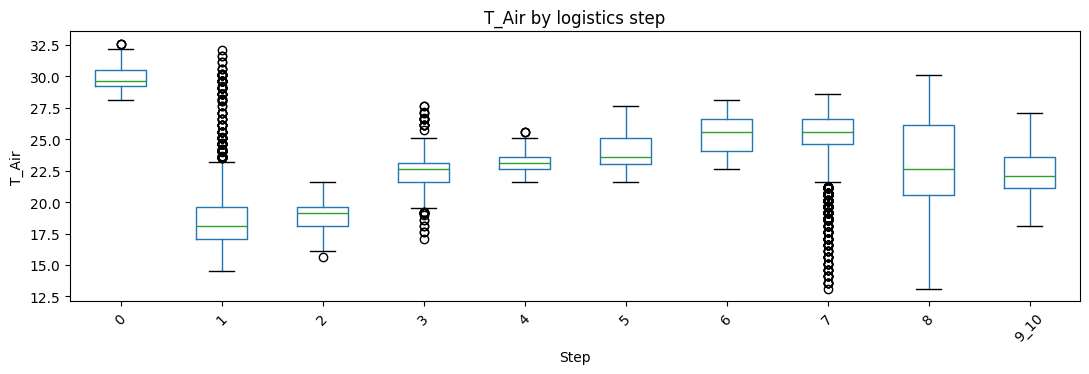

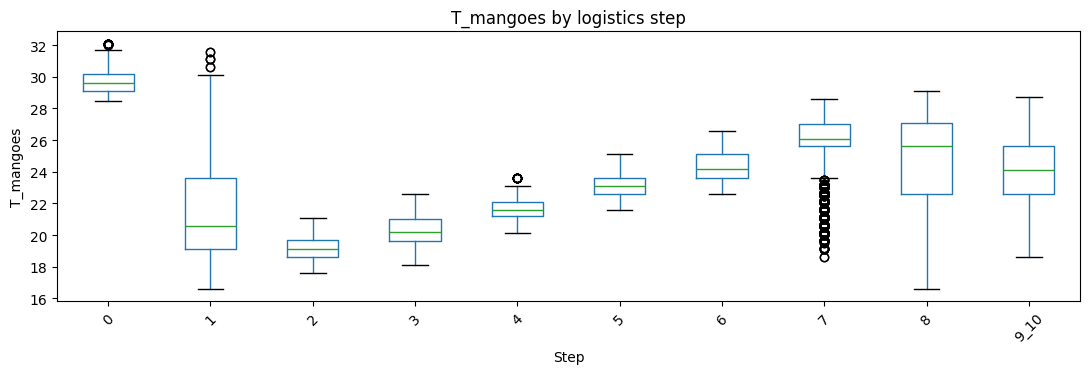

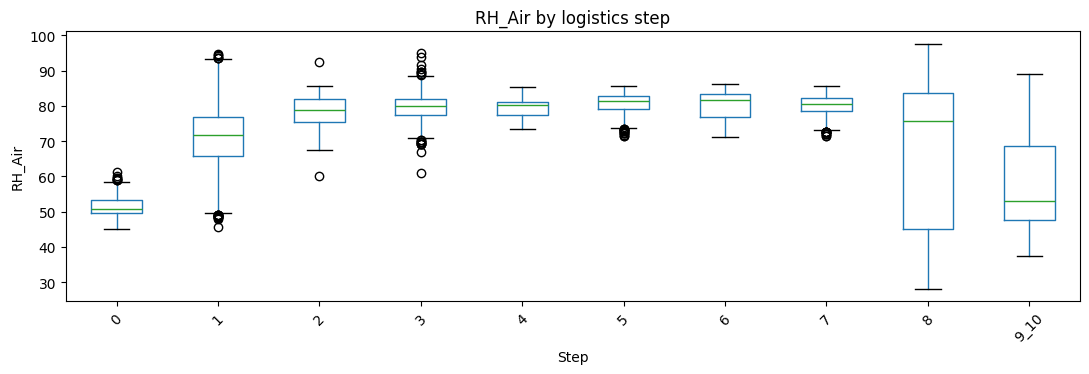

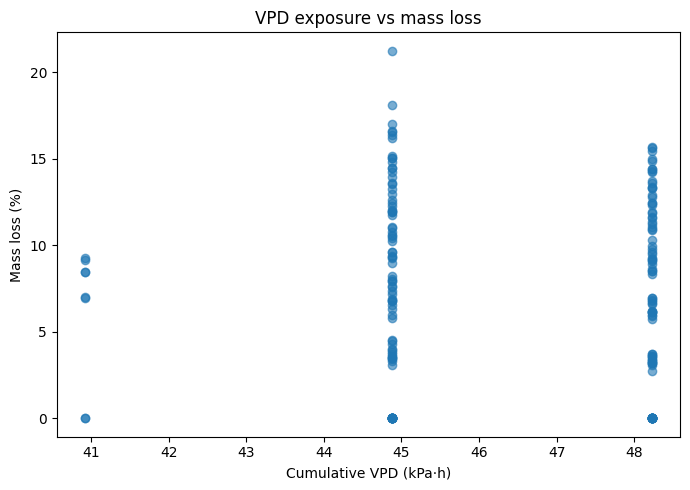

<Figure size 800x500 with 0 Axes>

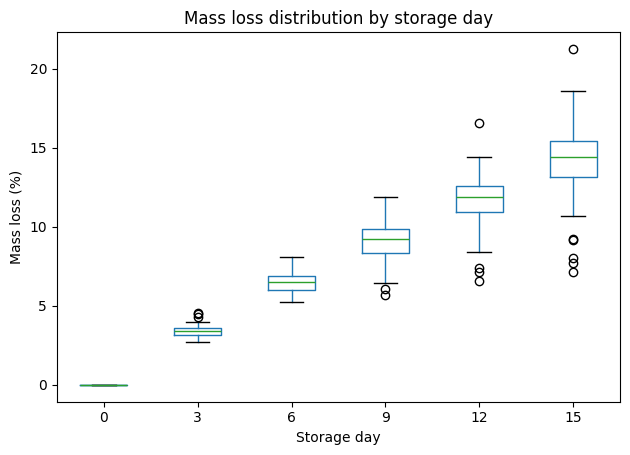

,T_Air,T_mangoes
T_Air,1.000000,0.779034
T_mangoes,0.779034,1.000000


{'raw_file_count': 563, 'sensor_step_file_count': 312, 'sensor_rows_clean': 20709, 'sensor_box_count': 31, 'quality_weight_rows': 280, 'quality_color_rows': 414, 'timestamp_bad_rows': 0, 'sensor_duplicate_rows_removed': 0}


In [20]:
# 9.1 Sensor distribution by step
if len(step_sensor):
    for col in ['T_Air','T_mangoes','RH_Air']:
        if col in step_sensor:
            ax=step_sensor.boxplot(column=col,by='step_id',rot=45,figsize=(11,4),grid=False)
            plt.suptitle(''); plt.title(f'{col} by logistics step'); plt.xlabel('Step'); plt.ylabel(col)
            plt.tight_layout(); plt.savefig(OUTPUT/'figures'/f'09_1_{col.lower()}_by_step.png',dpi=150); plt.show()

# 9.2 VPD vs mass loss at Box level (only where join exists)
if len(box_features) and len(weight_long) and 'vpd_integral_kpa_h' in box_features:
    rel=weight_long.merge(box_features[['box_id','vpd_integral_kpa_h']],on='box_id',how='inner').dropna(subset=['vpd_integral_kpa_h','mass_loss_pct'])
    if len(rel):
        plt.figure(figsize=(7,5)); plt.scatter(rel.vpd_integral_kpa_h,rel.mass_loss_pct,alpha=.6)
        plt.xlabel('Cumulative VPD (kPa·h)'); plt.ylabel('Mass loss (%)'); plt.title('VPD exposure vs mass loss')
        plt.tight_layout(); plt.savefig(OUTPUT/'figures'/'09_2_vpd_vs_mass_loss.png',dpi=150); plt.show()

# 9.3 Target distribution by storage day
if len(weight_long):
    plt.figure(figsize=(8,5)); weight_long.boxplot(column='mass_loss_pct',by='storage_day',grid=False)
    plt.suptitle(''); plt.title('Mass loss distribution by storage day'); plt.xlabel('Storage day'); plt.ylabel('Mass loss (%)')
    plt.tight_layout(); plt.savefig(OUTPUT/'figures'/'09_3_mass_loss_by_day.png',dpi=150); plt.show()

# 9.4 Multicollinearity diagnostic (Pearson correlation)
temp_cols=[c for c in ['T_Air','T_mangoes'] if c in step_sensor]
if temp_cols:
    corr=step_sensor[temp_cols].corr(method='pearson')
    corr.to_csv(OUTPUT/'tables'/'19_temperature_correlation.csv',encoding='utf-8-sig')
    display(corr)

# Data quality summary
quality_summary={
 'raw_file_count':int(len(all_files)), 'sensor_step_file_count':int(len(sensor_paths)),
 'sensor_rows_clean':int(len(sensor_clean)), 'sensor_box_count':int(step_sensor.box_id.nunique()) if len(step_sensor) else 0,
 'quality_weight_rows':int(len(weight_long)), 'quality_color_rows':int(len(color_long)),
 'timestamp_bad_rows':int(sensor_timestamp_audit.bad_timestamp.fillna(0).sum()) if len(sensor_timestamp_audit) else 0,
 'sensor_duplicate_rows_removed':int(clean_log.duplicate_removed.fillna(0).sum()) if len(clean_log) and 'duplicate_removed' in clean_log else 0,
}
with open(OUTPUT/'reports'/'09_eda_validation_summary.json','w',encoding='utf-8') as f: json.dump(quality_summary,f,ensure_ascii=False,indent=2)
print(quality_summary)

## STAGE 10 — Freeze dataset

Tạo bảng phân tích ở mức `Box × Mango × storage_day`. Một hàng là một lần quan sát quality của một quả tại một ngày; feature sensor ở cấp Box được lặp theo các quả trong Box và phải được diễn giải là **box-level exposure**, không phải exposure đo riêng từng quả.

Parquet là định dạng chính. CSV được xuất kèm để dễ kiểm tra. Nếu không có đủ Box/target, vẫn xuất các bảng kiểm tra nhưng không đóng dấu READY FOR MODELING.

In [21]:
final_dataset=pd.DataFrame()
if len(weight_long) and len(box_features):
    final_dataset=weight_long.merge(box_features,on='box_id',how='inner',suffixes=('','_box'))
    final_dataset['query_horizon_days']=final_dataset['storage_day']
    # Optional color target join; merge only matching fruit/day within same source/config context when possible.
    if len(color_long):
        color_target=c[['source_file','configuration','storage_temperature_nominal_c','box_id','mango_number','storage_day','target_delta_bstar']].drop_duplicates()
        final_dataset=final_dataset.merge(color_target,on=['configuration','storage_temperature_nominal_c','box_id','mango_number','storage_day'],how='left',suffixes=('','_color'))
    # Remove raw measurement columns from feature table only; keep identifiers and targets.
    id_target_cols=[c for c in ['source_file','configuration','storage_temperature_nominal_c','box_id','mango_number','measurement_date','storage_day','query_horizon_days','mass_g','mass_d0_g','mass_loss_pct','target_delta_bstar'] if c in final_dataset]
    feature_cols=[c for c in final_dataset.columns if c.startswith(('tair_','tmango_','rh_','delta_t_','vpd_','chilling_','heat_')) or c in ['transit_duration_hours','sensor_record_count','step_count']]
    final_dataset=final_dataset[id_target_cols+list(dict.fromkeys(feature_cols))].copy()
    final_dataset.to_csv(OUTPUT/'processed'/'mango_analysis_ready.csv',index=False,encoding='utf-8-sig')
    try:
        final_dataset.to_parquet(OUTPUT/'processed'/'mango_analysis_ready.parquet',index=False)
        parquet_ok=True
    except Exception as e:
        parquet_ok=False; print('Parquet export failed:',e)
else:
    parquet_ok=False

# Hash all source files to make data provenance reproducible.
def sha256_file(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''): h.update(chunk)
    return h.hexdigest()
checksum_rows=[{'relative_path':str(p.relative_to(DATA_RAW)),'size_bytes':p.stat().st_size,'sha256':sha256_file(p)} for p in all_files]
pd.DataFrame(checksum_rows).to_csv(OUTPUT/'reports'/'source_checksums.csv',index=False,encoding='utf-8-sig')

warnings_list=[]
if not len(sensor_boxes & quality_boxes): warnings_list.append('Không có Box overlap giữa sensor và quality; cần rà soát ID/selection design.')
if CONFIG['cold_injury_threshold_c'] is None: warnings_list.append('Chưa cấu hình chilling injury threshold; degree-hours đang để NaN.')
if CONFIG['heat_stress_threshold_c'] is None: warnings_list.append('Chưa cấu hình heat stress threshold; degree-hours đang để NaN.')
warnings_list.append('Timezone của timestamp chưa được xác nhận; đang giữ local-naive datetime.')
warnings_list.append('T_mangoes được giữ theo tên cột; vị trí logger cần xác minh bằng protocol gốc trước khi gọi là surface/core temperature.')
warnings_list.append('CNN embedding z in R^16 chưa được tạo; cần huấn luyện 1D-CNN ở modeling stage.')
warnings_list.append('RSL chưa được tính: cần định nghĩa ngưỡng chất lượng chấp nhận được và mô hình dự báo suy giảm theo thời gian.')
with open(OUTPUT/'reports'/'assumptions_and_warnings.md','w',encoding='utf-8') as f:
    f.write('# Assumptions and unresolved items\n\n')
    for item in warnings_list: f.write(f'- {item}\n')

ready=bool(len(final_dataset) and final_dataset['box_id'].nunique()>=CONFIG['group_k_folds'] and 'mass_loss_pct' in final_dataset and final_dataset.mass_loss_pct.notna().any() and parquet_ok)
status='READY FOR MODELING' if ready else 'NOT READY — REVIEW WARNINGS / DATA COVERAGE'
with open(OUTPUT/'reports'/'PIPELINE_STATUS.txt','w',encoding='utf-8') as f:
    f.write(status+'\n')
    f.write(json.dumps(quality_summary,ensure_ascii=False,indent=2)+'\n')
print('FINAL STATUS:',status)
print('Final dataset shape:',final_dataset.shape)
print('Outputs:',OUTPUT)

Parquet export failed: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'. pyarrow is required for parquet support. Use pip or conda to install pyarrow.
 - Missing optional dependency 'fastparquet'. fastparquet is required for parquet support. Use pip or conda to install fastparquet.
FINAL STATUS: NOT READY — REVIEW WARNINGS / DATA COVERAGE
Final dataset shape: (184, 39)
Outputs: /mnt/data/mango_quality_project/outputs


## Kết quả cần kiểm tra sau khi chạy

1. `outputs/tables/01_data_inventory.csv` — toàn bộ file được kiểm kê.
2. `outputs/tables/02_data_dictionary.csv` — từ điển biến và trạng thái cần rà soát.
3. `outputs/tables/03_sensor_box_step_mapping.csv` — mapping file sensor / Box / Step.
4. `outputs/processed/box_trajectories.parquet` — chuỗi nhiệt độ/độ ẩm theo Box.
5. `outputs/tables/10_weight_long.csv`, `11_color_long.csv`, `12_ph_long.csv`, `12_tss_long.csv` — dữ liệu chất lượng dạng long.
6. `outputs/tables/15_box_exposure_features.csv` — đặc trưng phơi nhiễm cấp Box.
7. `outputs/processed/mango_analysis_ready.parquet` — dataset modeling.
8. `outputs/reports/PIPELINE_STATUS.txt` — trạng thái cuối cùng.

**Không được sửa `PIPELINE_STATUS.txt` thành READY thủ công.** Chỉ pipeline mới được đóng dấu sau khi đạt điều kiện kiểm tra. Nếu status chưa READY, đọc `assumptions_and_warnings.md` và xử lý các điểm còn thiếu.